# Install the libraries

In [1]:
!pip install -q transformers

# Connect Google Drive

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


# Load the photo from Drive

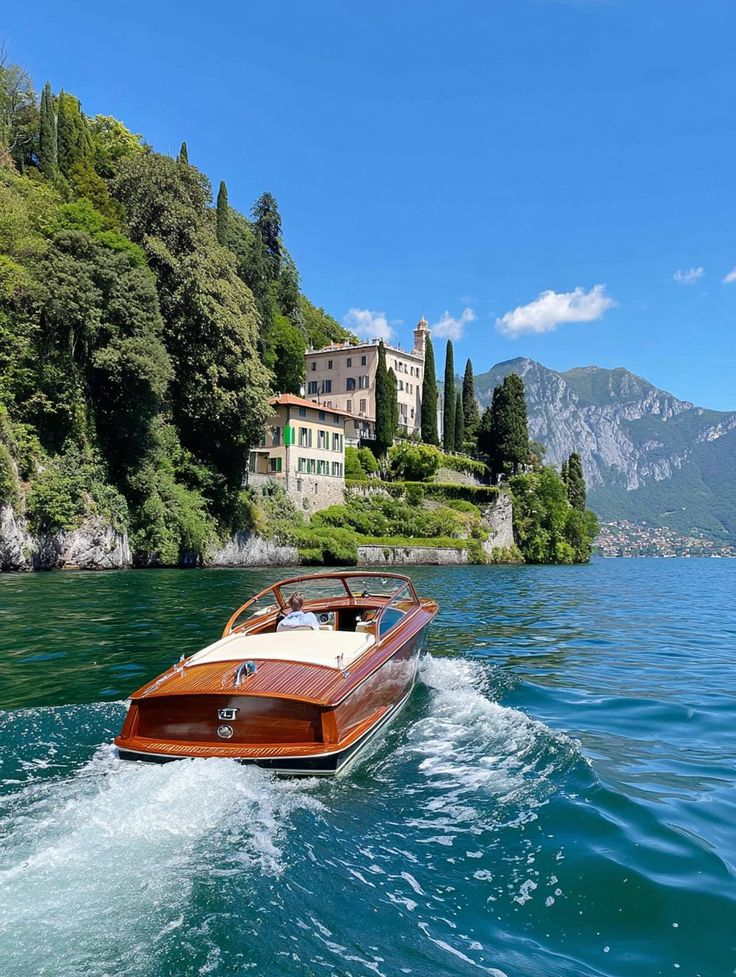

In [3]:
from PIL import Image
import os

image_path = (
    "/content/drive/MyDrive/"
    "random.jpeg"
)

image = Image.open(image_path).convert("RGB")

display(image)

# Load the AI model and generate text

In [4]:
import torch
from transformers import (
    BlipProcessor,
    BlipForConditionalGeneration
)

model_id = "Salesforce/blip-image-captioning-base"

processor = BlipProcessor.from_pretrained(model_id)
model = BlipForConditionalGeneration.from_pretrained(
    model_id
)

device = (
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

inputs = processor(
    images=image,
    return_tensors="pt"
).to(device)

with torch.no_grad():
    output = model.generate(**inputs, max_new_tokens=50)

caption = processor.decode(
    output[0],
    skip_special_tokens=True
)

print("Generated caption:", caption)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

Generated caption: a boat traveling on the water near a small island
